<a href="https://colab.research.google.com/github/2303A51889/PYTHON-LAB-EXAM/blob/main/Cotton_Crop_XAI_ResNet50_CBAM_Xception.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [21]:
!pip -q install kaggle scikit-learn seaborn pandas matplotlib pillow

In [22]:
import os
import json
import random
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


In [23]:
from google.colab import files

uploaded = files.upload()  # Select kaggle.json

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API configured.")

Saving kaggle.json to kaggle (2).json
Kaggle API configured.


In [24]:
!kaggle datasets download \
    -d rupankarmajumdar/crop-pests-dataset \
    -p /content/dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/rupankarmajumdar/crop-pests-dataset
License(s): MIT
100% 537M/537M [00:04<00:00, 121MB/s]



In [25]:
DATA_ROOT = "/content/dataset"

for root, dirs, files_list in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)

    if level <= 3:
        print(
            "  " * level,
            os.path.basename(root) or root,
            f"| {len(files_list)} files"
        )

 dataset | 1 files
   train | 0 files
     labels | 11502 files
     images | 11502 files
   valid | 0 files
     labels | 1095 files
     images | 1095 files
   test | 0 files
     labels | 546 files
     images | 546 files


Total images found: 13143


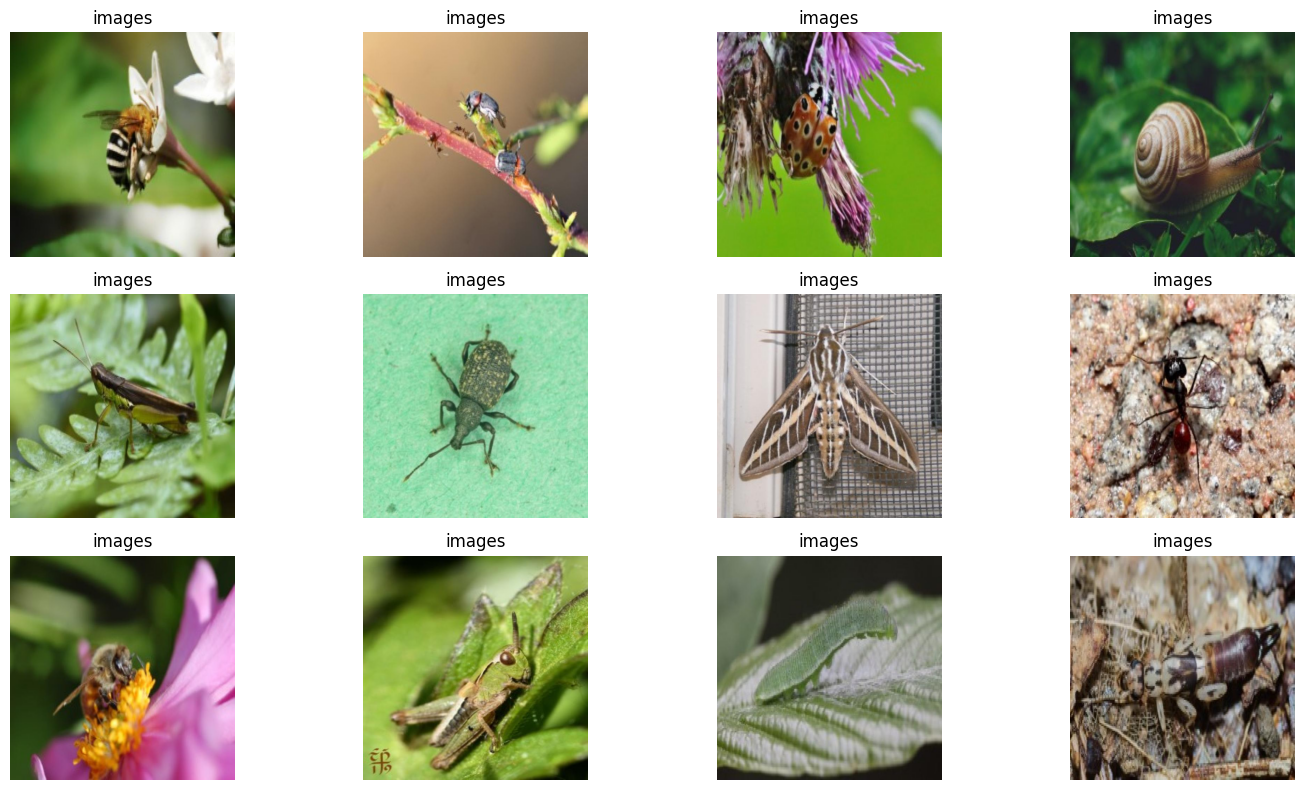

In [26]:
from PIL import Image

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = [
    p for p in Path(DATA_ROOT).rglob("*")
    if p.suffix.lower() in image_extensions
]

print("Total images found:", len(image_paths))

plt.figure(figsize=(15, 8))

for i, path in enumerate(image_paths[:12]):
    try:
        img = Image.open(path).convert("RGB")
        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(path.parent.name)
        plt.axis("off")
    except Exception as e:
        print("Could not open:", path)

plt.tight_layout()
plt.show()

In [27]:
# CHANGE THIS if Step 4 showed that the class folders
# are inside a nested directory.
CLASS_ROOT = "/content/dataset"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

class_dirs = sorted([
    p for p in Path(CLASS_ROOT).iterdir()
    if p.is_dir()
    and any(
        f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        for f in p.rglob("*")
    )
])

if len(class_dirs) < 2:
    raise ValueError(
        "Could not find at least two class folders. "
        "Check CLASS_ROOT and the output from Step 4."
    )

class_names = [p.name for p in class_dirs]
class_to_index = {name: i for i, name in enumerate(class_names)}

paths, labels = [], []

for class_dir in class_dirs:
    for p in class_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            paths.append(str(p))
            labels.append(class_to_index[class_dir.name])

paths = np.array(paths)
labels = np.array(labels, dtype=np.int32)

print("Classes:", class_names)
print("Number of classes:", len(class_names))
print("Total images:", len(paths))

if len(paths) == 0:
    raise ValueError("No images found.")

Classes: ['test', 'train', 'valid']
Number of classes: 3
Total images: 13143


,image_count
test,546
train,11502
valid,1095


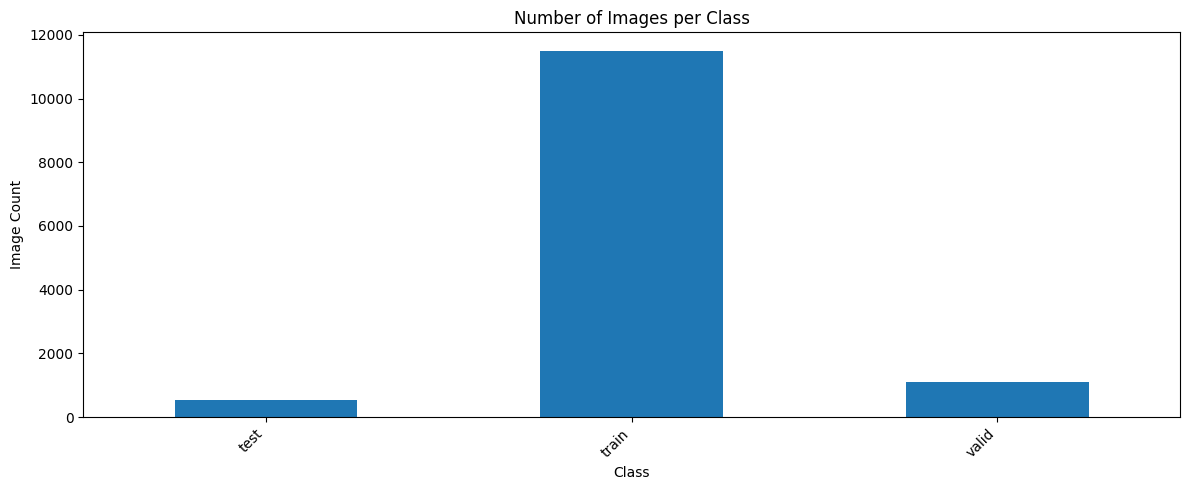

In [28]:
counts = pd.Series(
    [class_names[i] for i in labels]
).value_counts().reindex(class_names, fill_value=0)

display(counts.rename("image_count").to_frame())

plt.figure(figsize=(12, 5))
counts.plot(kind="bar")
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Image Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print(f"Training images:   {len(train_paths)}")
print(f"Validation images: {len(val_paths)}")
print(f"Test images:       {len(test_paths)}")

Training images:   9200
Validation images: 1971
Test images:       1972


In [30]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16

def make_dataset(image_paths, image_labels, image_size, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, image_labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(image_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image, channels=3, expand_animations=False
        )
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, image_size)
        image = tf.cast(image, tf.float32)
        return image, label

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

def datasets_for_size(image_size):
    train_ds = make_dataset(
        train_paths, train_labels, image_size, training=True
    )
    val_ds = make_dataset(
        val_paths, val_labels, image_size
    )
    test_ds = make_dataset(
        test_paths, test_labels, image_size
    )
    return train_ds, val_ds, test_ds

In [31]:
def cbam_block(feature_map, reduction_ratio=8):
    channels = int(feature_map.shape[-1])

    # Channel attention
    shared_dense_1 = layers.Dense(
        max(channels // reduction_ratio, 8),
        activation="relu"
    )
    shared_dense_2 = layers.Dense(channels)

    avg_pool = layers.GlobalAveragePooling2D()(feature_map)
    max_pool = layers.GlobalMaxPooling2D()(feature_map)

    avg_pool = layers.Reshape((1, 1, channels))(avg_pool)
    max_pool = layers.Reshape((1, 1, channels))(max_pool)

    avg_attention = shared_dense_2(shared_dense_1(avg_pool))
    max_attention = shared_dense_2(shared_dense_1(max_pool))

    channel_attention = layers.Activation("sigmoid")(
        layers.Add()([avg_attention, max_attention])
    )

    x = layers.Multiply()([feature_map, channel_attention])

    # Spatial attention
    avg_spatial = layers.Lambda(
        lambda t: tf.reduce_mean(t, axis=-1, keepdims=True)
    )(x)

    max_spatial = layers.Lambda(
        lambda t: tf.reduce_max(t, axis=-1, keepdims=True)
    )(x)

    spatial = layers.Concatenate(axis=-1)(
        [avg_spatial, max_spatial]
    )

    spatial_attention = layers.Conv2D(
        1, kernel_size=7, padding="same", activation="sigmoid"
    )(spatial)

    output = layers.Multiply()([x, spatial_attention])
    return output


def build_resnet50_cbam(num_classes):
    inputs = layers.Input(shape=(224, 224, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomContrast(0.10)(x)

    # ResNet50-specific preprocessing
    x = layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    )(x)

    backbone = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3)
    )
    backbone.trainable = False

    x = backbone(x, training=False)
    x = cbam_block(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = models.Model(
        inputs, outputs, name="ResNet50_CBAM"
    )

    return model, backbone


resnet_train_ds, resnet_val_ds, resnet_test_ds = datasets_for_size(
    (224, 224)
)

resnet_model, resnet_backbone = build_resnet50_cbam(
    len(class_names)
)

resnet_model.summary()

Model: "ResNet50_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 224, 224,  │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 224, 224,  │          0 │ random_rotation_… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast_1   │ (None, 224, 224,  │          0 │ random_zoom_1[0]… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 224, 224,  │          0 │ random_contrast_… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ lambda_3[0][0]    │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 1,      │          0 │ global_average_p… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 1, 1,      │          0 │ global_max_pooli… │
│                     │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1, 1, 256) │    524,544 │ reshape_2[0][0],  │
│                     │                   │            │ reshape_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1, 1,      │    526,336 │ dense_4[0][0],    │
│                     │ 2048)             │            │ dense_4[1][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 1, 1,      │          0 │ dense_5[0][0],    │
│                     │ 2048)             │            │ dense_5[1][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 1, 1,      │          0 │ add_1[0][0]       │
│ (Activation)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 7, 7,      │          0 │ resnet50[0][0],   │
│ (Multiply)          │ 2048)             │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_4 (Lambda)   │ (None, 7, 7, 1)   │          0 │ multiply_2[0][0]

 Total params: 25,172,198 (96.02 MB)

 Trainable params: 1,580,390 (6.03 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [32]:
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(np.unique(train_labels), weights)
}

print("Class weights:", class_weights)

Class weights: {0: 8.027923211169284, 1: 0.3809050635531818, 2: 3.9982616253802696}


In [35]:
resnet_backbone.trainable = True

# Freeze earlier layers and fine-tune only the last 30 layers.
for layer in resnet_backbone.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning.
for layer in resnet_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet_finetune = resnet_model.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=12,
    class_weight=class_weights,
    callbacks=resnet_callbacks
)

resnet_model.save("/content/resnet50_cbam_final.keras")

Epoch 1/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - accuracy: 0.4845 - loss: 1.2507
Epoch 1: val_loss improved from None to 0.85326, saving model to /content/resnet50_cbam_best.keras

Epoch 1: finished saving model to /content/resnet50_cbam_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 92s 141ms/step - accuracy: 0.4712 - loss: 1.1931 - val_accuracy: 0.5053 - val_loss: 0.8533 - learning_rate: 1.0000e-05
Epoch 2/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.4521 - loss: 1.1585
Epoch 2: val_loss improved from 0.85326 to 0.84538, saving model to /content/resnet50_cbam_best.keras

Epoch 2: finished saving model to /content/resnet50_cbam_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 78s 135ms/step - accuracy: 0.4571 - loss: 1.0939 - val_accuracy: 0.5302 - val_loss: 0.8454 - learning_rate: 1.0000e-05
Epoch 3/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.4548 - loss: 1.0173
Epoch 3: val_loss did not improve from 0.84538
575/575 ━━━━━━━━━━━━━━━━━━━━ 79s 130ms/step - accuracy

In [38]:
def build_xception(num_classes):
    inputs = layers.Input(shape=(299, 299, 3))

    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomContrast(0.10)(x)

    # Xception-specific preprocessing: pixels -> [-1, 1]
    x = layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1
    )(x)

    backbone = tf.keras.applications.Xception(
        include_top=False,
        weights="imagenet",
        input_shape=(299, 299, 3)
    )
    backbone.trainable = False

    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    model = models.Model(inputs, outputs, name="Xception")
    return model, backbone


xception_train_ds, xception_val_ds, xception_test_ds = (
    datasets_for_size((299, 299))
)

xception_model, xception_backbone = build_xception(
    len(class_names)
)

xception_model.summary()

Model: "Xception"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_3 (RandomFlip)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 299, 299, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_3               │ (None, 299, 299, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,394,987 (81.62 MB)

 Trainable params: 529,411 (2.02 MB)

 Non-trainable params: 20,865,576 (79.60 MB)

In [37]:
xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

xception_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/xception_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history_xception_head = xception_model.fit(
    xception_train_ds,
    validation_data=xception_val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=xception_callbacks
)

Epoch 1/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.4357 - loss: 2.4292
Epoch 1: val_loss improved from None to 0.96169, saving model to /content/xception_best.keras

Epoch 1: finished saving model to /content/xception_best.keras
575/575 ━━━━━━━━━━━━━━━━━━━━ 124s 203ms/step - accuracy: 0.4464 - loss: 2.1133 - val_accuracy: 0.5561 - val_loss: 0.9617 - learning_rate: 0.0010
Epoch 2/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.4773 - loss: 1.1944
Epoch 2: val_loss did not improve from 0.96169
575/575 ━━━━━━━━━━━━━━━━━━━━ 114s 198ms/step - accuracy: 0.4625 - loss: 1.1584 - val_accuracy: 0.3937 - val_loss: 1.1264 - learning_rate: 0.0010
Epoch 3/15
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.4876 - loss: 1.0336
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.

Epoch 3: val_loss did not improve from 0.96169
575/575 ━━━━━━━━━━━━━━━━━━━━ 113s 197ms/step - accuracy: 0.4777 - loss: 1.0334 - val_accuracy: 0.4257 - val_loss: 1.0

In [39]:
xception_backbone.trainable = True

# Fine-tune the later layers only.
for layer in xception_backbone.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen.
for layer in xception_backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

xception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_xception_finetune = xception_model.fit(
    xception_train_ds,
    validation_data=xception_val_ds,
    epochs=12,
    class_weight=class_weights,
    callbacks=xception_callbacks
)

xception_model.save("/content/xception_final.keras")

Epoch 1/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.4462 - loss: 1.6441
Epoch 1: val_loss did not improve from 0.84377
575/575 ━━━━━━━━━━━━━━━━━━━━ 166s 261ms/step - accuracy: 0.4351 - loss: 1.5944 - val_accuracy: 0.4044 - val_loss: 1.1813 - learning_rate: 1.0000e-05
Epoch 2/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.4399 - loss: 1.3747
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.

Epoch 2: val_loss did not improve from 0.84377
575/575 ━━━━━━━━━━━━━━━━━━━━ 146s 254ms/step - accuracy: 0.4352 - loss: 1.3331 - val_accuracy: 0.4201 - val_loss: 1.1338 - learning_rate: 1.0000e-05
Epoch 3/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.4614 - loss: 1.2310
Epoch 3: val_loss did not improve from 0.84377
575/575 ━━━━━━━━━━━━━━━━━━━━ 146s 254ms/step - accuracy: 0.4514 - loss: 1.1955 - val_accuracy: 0.4450 - val_loss: 1.1215 - learning_rate: 3.0000e-06
Epoch 4/12
575/575 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.43

In [41]:
def combine_histories(*histories):
    combined = {}

    for history in histories:
        for key, values in history.history.items():
            combined.setdefault(key, [])
            combined[key].extend(values)

    return combined


resnet_history = combine_histories(
    history_resnet_head,
    history_resnet_finetune
)

xception_history = combine_histories(
    history_xception_head,
    history_xception_finetune
)

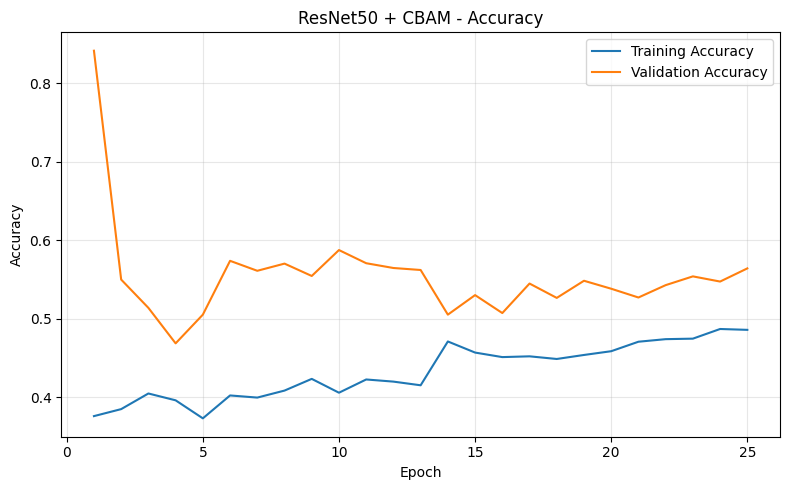

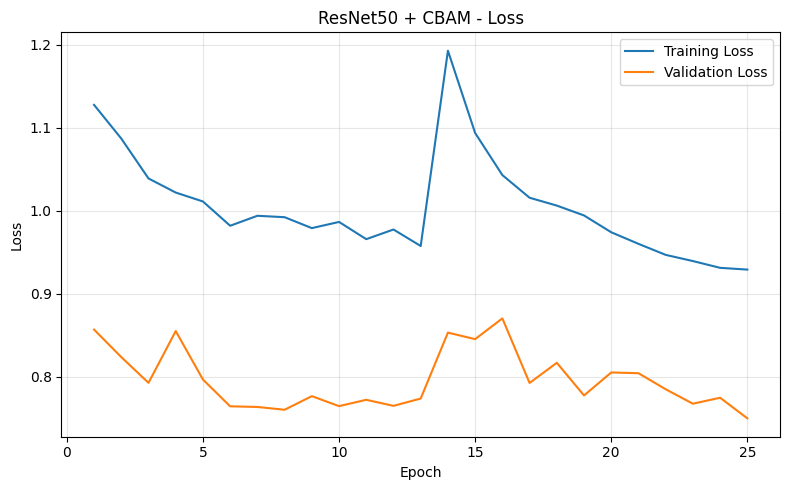

In [42]:
def plot_training_history(history, model_name, save_prefix):
    epochs = range(1, len(history["loss"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["accuracy"], label="Training Accuracy")
    plt.plot(epochs, history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_accuracy.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history["loss"], label="Training Loss")
    plt.plot(epochs, history["val_loss"], label="Validation Loss")
    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{save_prefix}_loss.png", dpi=300)
    plt.show()


plot_training_history(
    resnet_history,
    "ResNet50 + CBAM",
    "/content/resnet50_cbam"
)

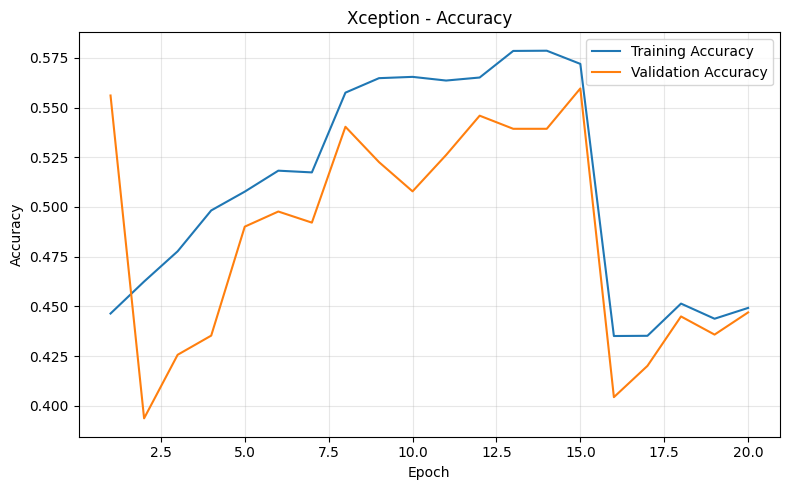

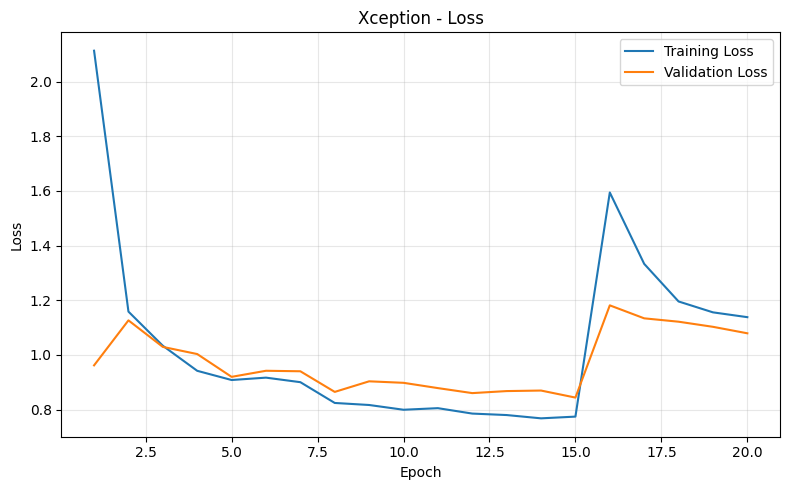

In [43]:
plot_training_history(
    xception_history,
    "Xception",
    "/content/xception"
)

In [44]:
def evaluate_model(model, test_ds, y_true, model_name):
    probabilities = model.predict(test_ds, verbose=1)
    y_pred = np.argmax(probabilities, axis=1)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Precision (Weighted)": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall (Weighted)": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-score (Weighted)": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    print(f"\n{model_name} — Classification Report")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, y_pred, labels=np.arange(len(class_names))
    )

    plt.figure(figsize=(max(8, len(class_names)), 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        f"/content/{model_name.lower().replace(' ', '_').replace('+', 'cbam')}_confusion_matrix.png",
        dpi=300
    )
    plt.show()

    return metrics, y_pred, probabilities

124/124 ━━━━━━━━━━━━━━━━━━━━ 16s 94ms/step

ResNet50 + CBAM — Classification Report
              precision    recall  f1-score   support

        test       0.09      0.65      0.16        82
       train       0.99      0.63      0.77      1726
       valid       0.19      0.32      0.24       164

    accuracy                           0.60      1972
   macro avg       0.42      0.53      0.39      1972
weighted avg       0.88      0.60      0.70      1972



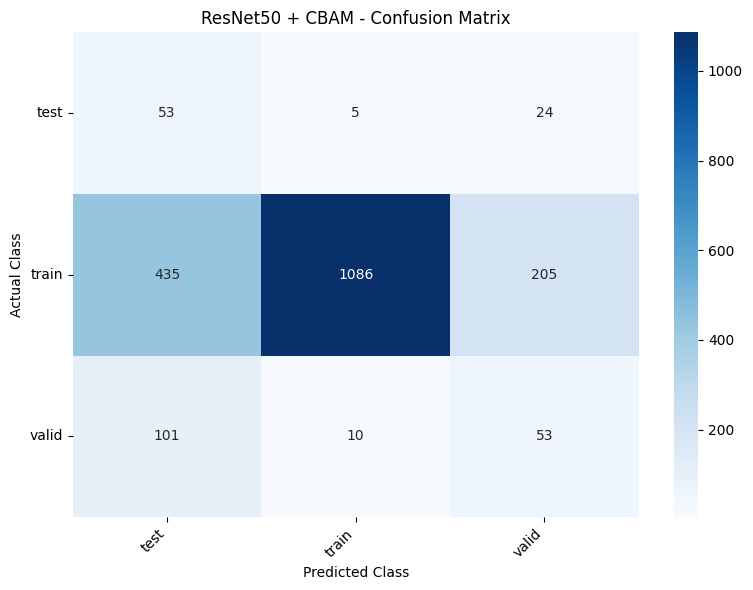

124/124 ━━━━━━━━━━━━━━━━━━━━ 22s 169ms/step

Xception — Classification Report
              precision    recall  f1-score   support

        test       0.06      0.55      0.11        82
       train       0.97      0.39      0.56      1726
       valid       0.11      0.38      0.17       164

    accuracy                           0.40      1972
   macro avg       0.38      0.44      0.28      1972
weighted avg       0.86      0.40      0.51      1972



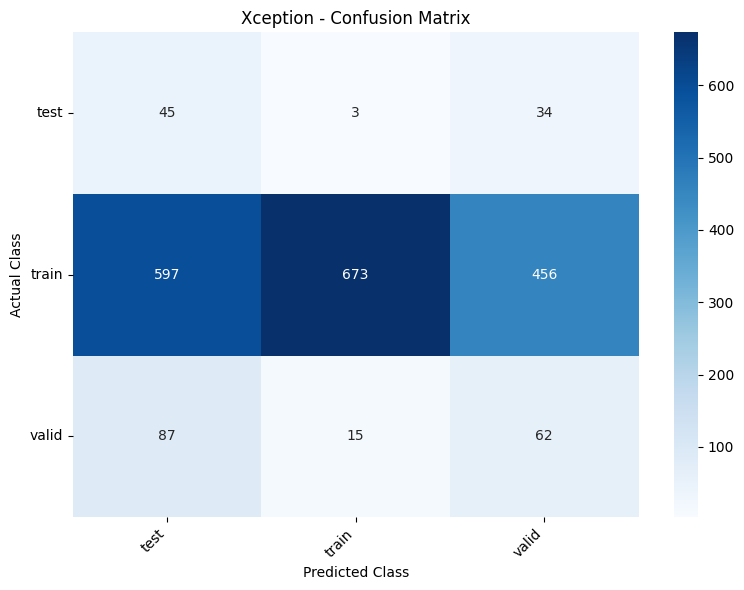

In [45]:
resnet_metrics, resnet_predictions, resnet_probabilities = evaluate_model(
    resnet_model,
    resnet_test_ds,
    test_labels,
    "ResNet50 + CBAM"
)

xception_metrics, xception_predictions, xception_probabilities = evaluate_model(
    xception_model,
    xception_test_ds,
    test_labels,
    "Xception"
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro),Precision (Weighted),Recall (Weighted),F1-score (Weighted)
0,ResNet50 + CBAM,0.6045,0.4214,0.5329,0.3880,0.8827,0.6045,0.6988
1,Xception,0.3955,0.3827,0.4389,0.2803,0.8644,0.3955,0.5064


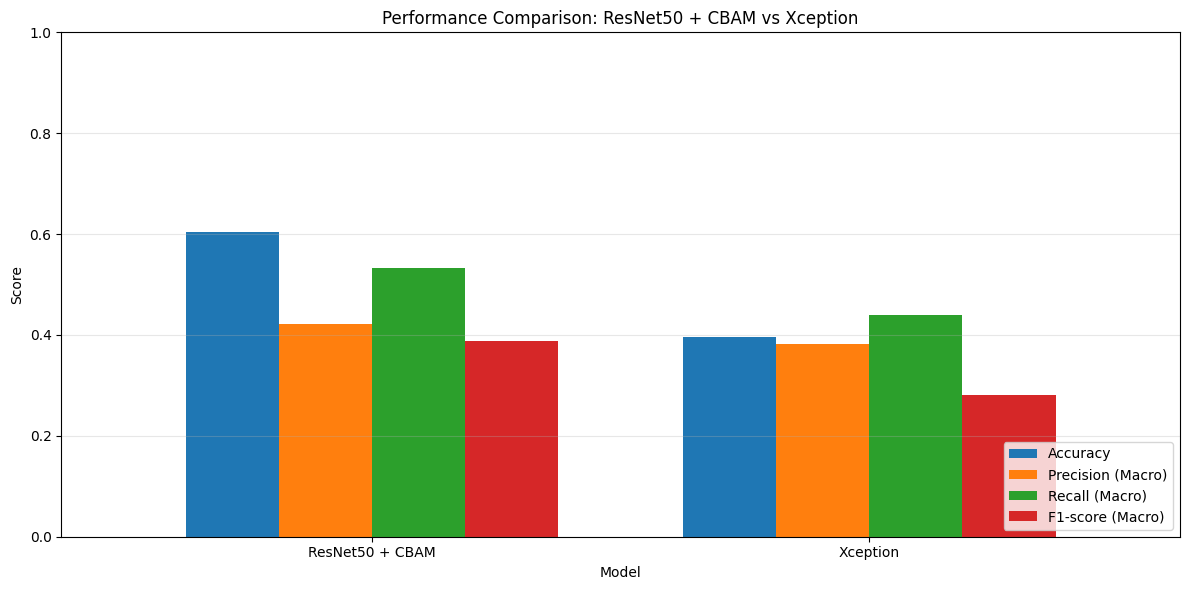

In [46]:
results_df = pd.DataFrame([
    resnet_metrics,
    xception_metrics
])

display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.select_dtypes(include="number").columns
    })
)

metric_columns = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]

plot_df = results_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.75
)

ax.set_title("Performance Comparison: ResNet50 + CBAM vs Xception")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/content/model_performance_comparison.png", dpi=300)
plt.show()

results_df.to_csv("/content/model_evaluation_results.csv", index=False)

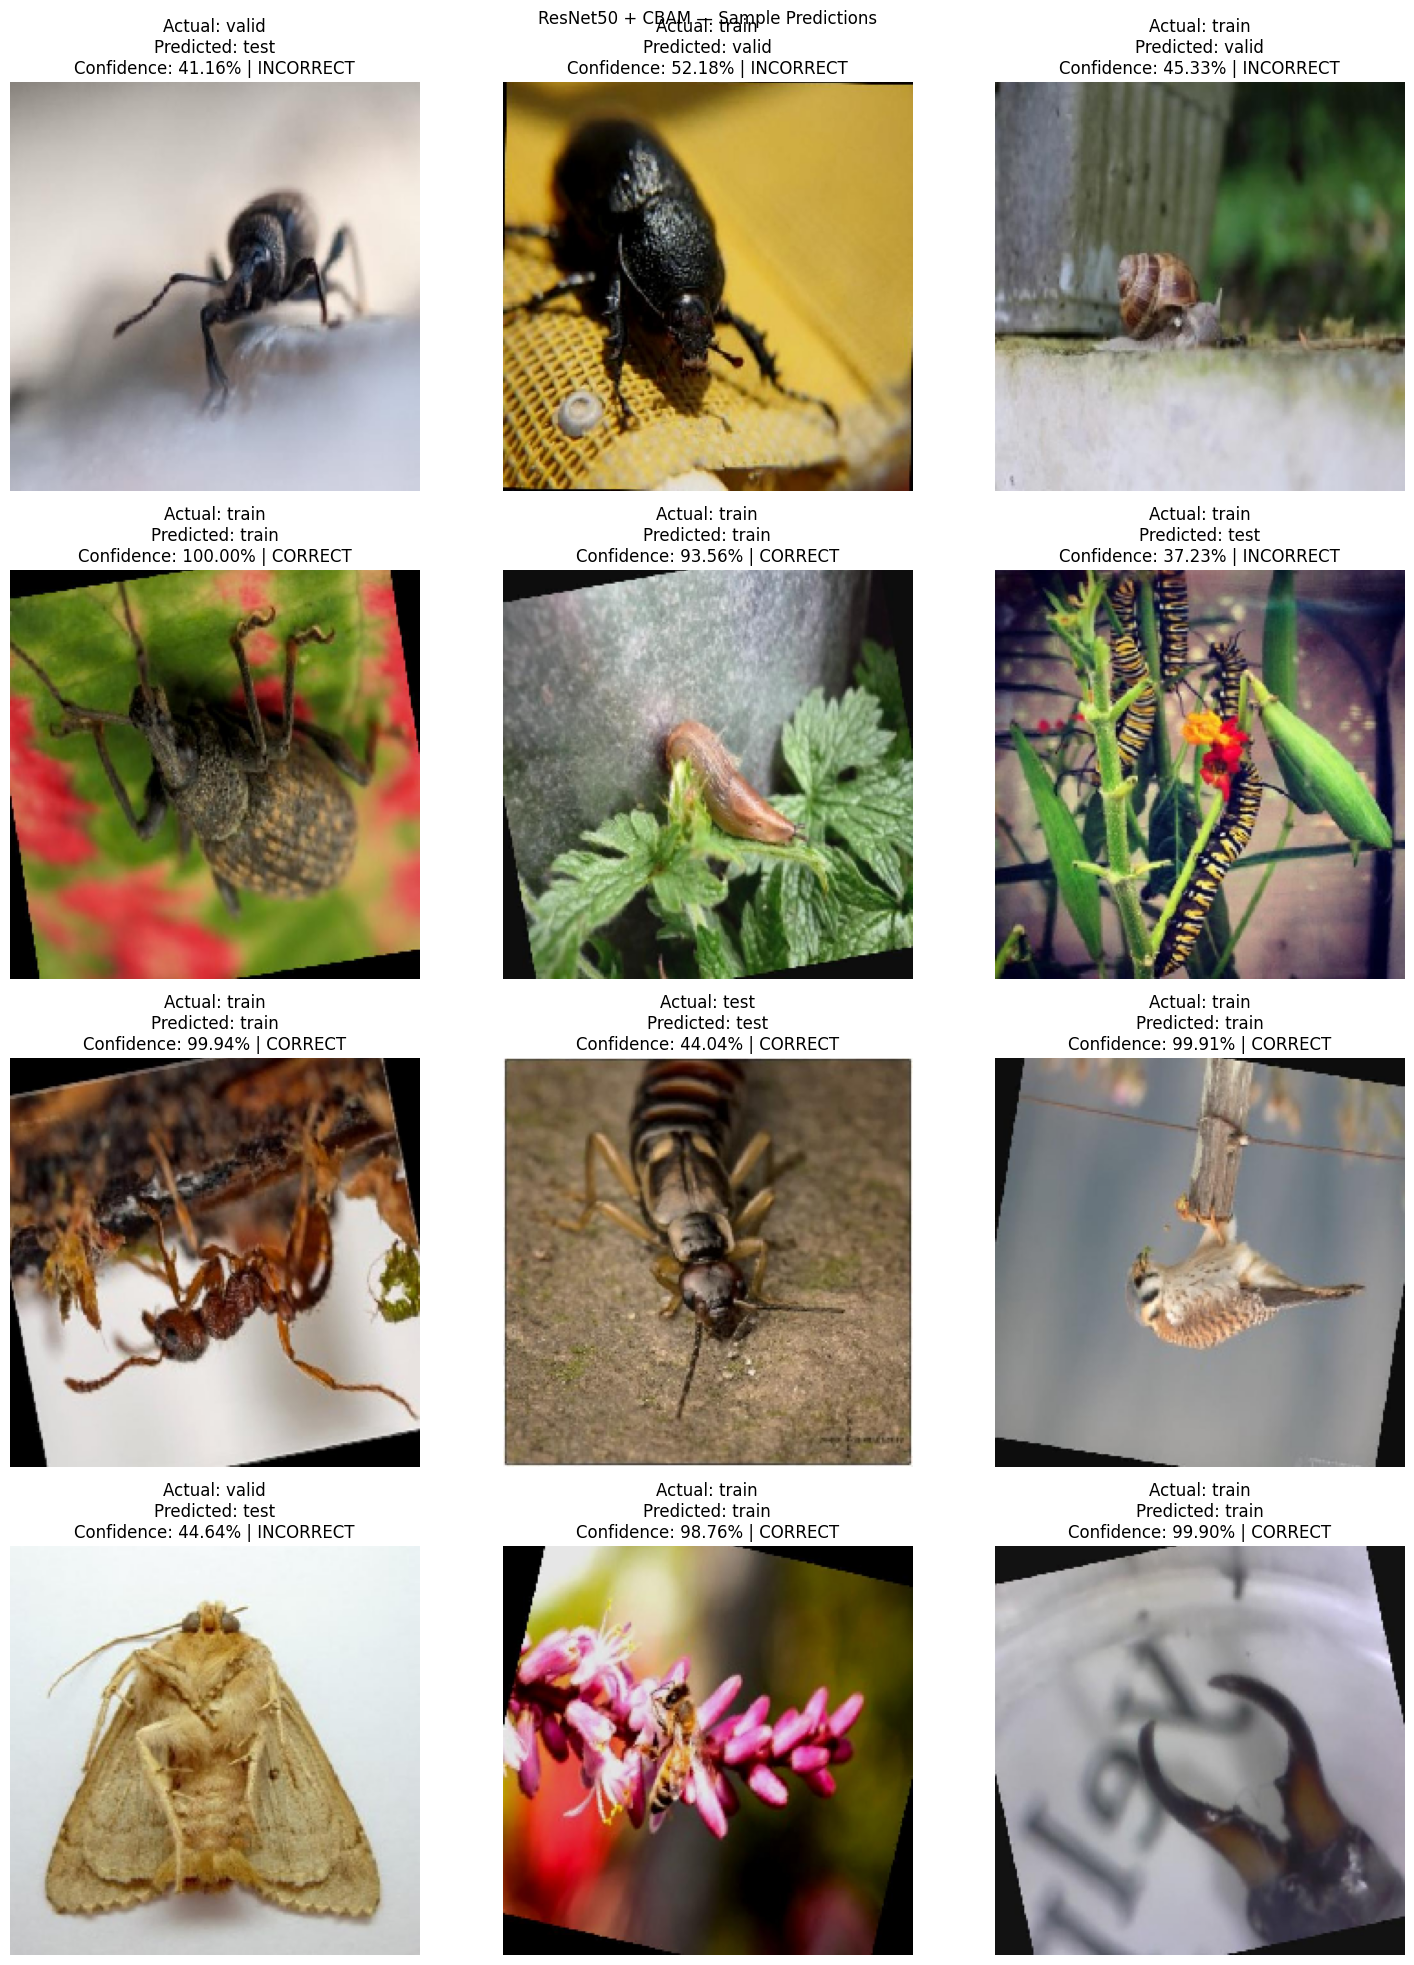

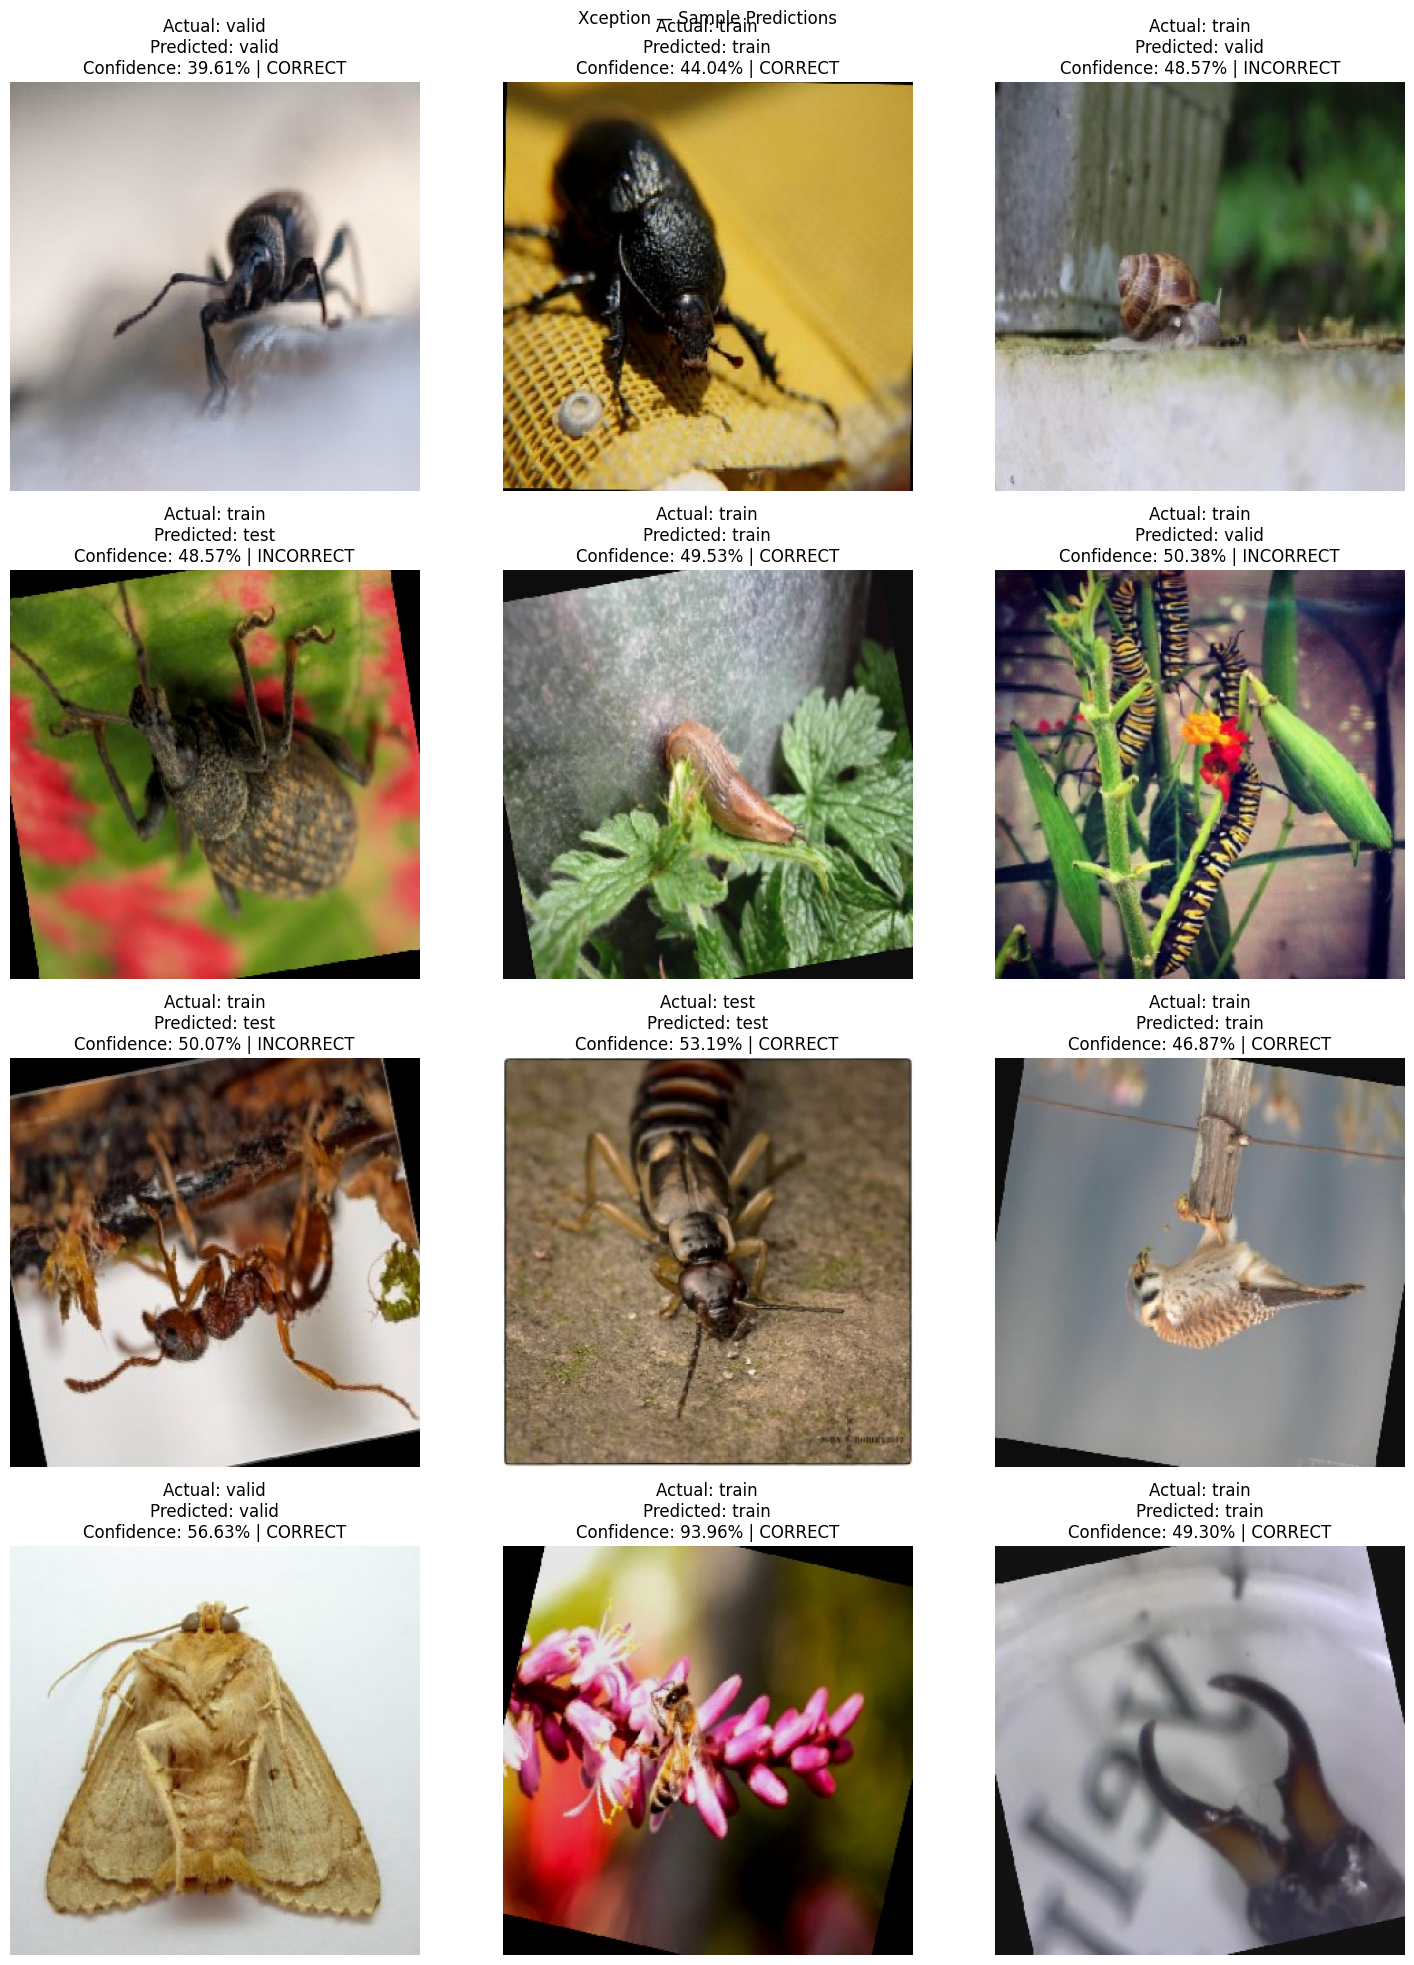

In [47]:
def show_predictions(model, image_paths, true_labels, image_size,
                     model_name, max_images=12):
    rng = np.random.default_rng(SEED)
    indices = rng.choice(
        len(image_paths),
        size=min(max_images, len(image_paths)),
        replace=False
    )

    selected_paths = image_paths[indices]
    selected_labels = true_labels[indices]

    images = []

    for path in selected_paths:
        img = tf.keras.utils.load_img(
            path, target_size=image_size
        )
        images.append(tf.keras.utils.img_to_array(img))

    batch = np.array(images, dtype=np.float32)
    probabilities = model.predict(batch, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    cols = 3
    rows = int(np.ceil(len(indices) / cols))

    plt.figure(figsize=(15, 5 * rows))

    for j, (img, actual, pred, probs) in enumerate(
        zip(images, selected_labels, predictions, probabilities)
    ):
        plt.subplot(rows, cols, j + 1)
        plt.imshow(img.astype("uint8"))

        correct = actual == pred
        status = "CORRECT" if correct else "INCORRECT"

        plt.title(
            f"Actual: {class_names[actual]}\n"
            f"Predicted: {class_names[pred]}\n"
            f"Confidence: {probs[pred]:.2%} | {status}"
        )
        plt.axis("off")

    plt.suptitle(f"{model_name} — Sample Predictions")
    plt.tight_layout()
    plt.savefig(
        f"/content/{model_name.lower().replace(' ', '_').replace('+', 'cbam')}_predictions.png",
        dpi=300
    )
    plt.show()


show_predictions(
    resnet_model, test_paths, test_labels,
    (224, 224), "ResNet50 + CBAM"
)

show_predictions(
    xception_model, test_paths, test_labels,
    (299, 299), "Xception"
)

In [48]:
# Save a combined results table
results_df.to_csv(
    "/content/model_evaluation_results.csv",
    index=False
)

# Package the models, plots and metrics
files_to_package = [
    "/content/resnet50_cbam_final.keras",
    "/content/xception_final.keras",
    "/content/model_evaluation_results.csv",
    "/content/model_performance_comparison.png",
    "/content/resnet50_cbam_accuracy.png",
    "/content/resnet50_cbam_loss.png",
    "/content/xception_accuracy.png",
    "/content/xception_loss.png"
]

# Include generated confusion matrices and prediction figures
files_to_package += [
    str(p) for p in Path("/content").glob("*confusion_matrix.png")
]
files_to_package += [
    str(p) for p in Path("/content").glob("*predictions.png")
]

with zipfile.ZipFile(
    "/content/crop_pest_model_results.zip", "w"
) as zf:
    for file_path in files_to_package:
        if os.path.exists(file_path):
            zf.write(file_path, arcname=os.path.basename(file_path))

print("Results package created.")

Results package created.


In [49]:
from google.colab import files

files.download("/content/crop_pest_model_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>